# Challenge - Starter notebook: skin lesions (DermaMNIST)

This notebook is your **starting point** for the challenge. We go through it together on day 4.
It does everything once, in the simplest way:
1. load the data and **look at it**,
2. train a **baseline CNN** (= "A" in the handout),
3. **evaluate** it on the validation images with the challenge metrics,
4. **export** the model as `model.pt` - this file is what you hand in.

Then it is your turn: improve the baseline (= "B") - ideas at the end.

A **CPU runtime is enough**: the baseline trains in under a minute. A GPU (*Runtime → Change runtime type → T4 GPU*)
helps for bigger models.

**The golden rule:** you **train** only on the train images and **choose** models and settings on the val images.
The official **test** images may only be used to *report* the results of your final models - never for training.

## Setup - run these two cells first
The first cell installs MedMNIST and loads DermaMNIST: 28 × 28 colour images of skin lesions, 7 classes.
The images become tensors `(N, 3, 28, 28)` with values 0...1, then they are **normalised** with the mean and
spread of the *training* images (one number per colour channel).

⚠️ Keep `MEAN`, `STD` and `normalize` exactly like this - the evaluation script and the app use the same numbers.

In [1]:

%pip install -q medmnist
import os

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from medmnist import DermaMNIST
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import v2

MEAN = [0.7631, 0.5381, 0.5614]     # channel mean of the training images (R, G, B)
STD = [0.1366, 0.1543, 0.1692]      # channel spread of the training images
normalize = v2.Normalize(MEAN, STD)
CLASSES = ["actinic keratoses", "basal cell carcinoma", "benign keratosis", "dermatofibroma",
           "melanoma", "melanocytic nevi", "vascular lesions"]


def load(split):
    """DermaMNIST split as tensors: images (N, 3, 28, 28) normalised, labels (N,)."""
    os.makedirs("data", exist_ok=True)
    d = DermaMNIST(split=split, download=True, size=28, root="data")
    X = torch.tensor(d.imgs).permute(0, 3, 1, 2).float() / 255   # (N, 28, 28, 3) -> (N, 3, 28, 28), 0...1
    y = torch.tensor(d.labels).squeeze(1).long()
    return normalize(X), y


X_train, y_train = load("train")
X_val, y_val = load("val")
print("training:", tuple(X_train.shape), "  validation:", tuple(X_val.shape))

Note: you may need to restart the kernel to use updated packages.
training: (7007, 3, 28, 28)   validation: (1003, 3, 28, 28)


The second cell defines helpers for plots and metrics. **Just run it - you do not need to read it now.**
PyTorch has no built-in metrics, so we use scikit-learn **only for the metrics**.

In [2]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             recall_score)


def show_examples(X, y, per_class=6):
    """A grid: one row per class, a few example images."""
    fig, axes = plt.subplots(len(CLASSES), per_class, figsize=(per_class * 1.2, len(CLASSES) * 1.25))
    for c in range(len(CLASSES)):
        idx = (y == c).nonzero().squeeze(1)[:per_class]
        for k, ax in enumerate(axes[c]):
            img = X[idx[k]].permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)   # undo the normalisation
            ax.imshow(img.clamp(0, 1)); ax.axis("off")
        axes[c][0].set_title(CLASSES[c], fontsize=8, loc="left")
    plt.tight_layout(); plt.show()


def predict(model, X, batch_size=512):
    """Predicted class for every image (no gradients, eval mode)."""
    model.eval()
    with torch.no_grad():
        return torch.cat([model(X[i:i + batch_size]).argmax(1) for i in range(0, len(X), batch_size)])


def challenge_metrics(y_true, y_pred, show=True):
    """The challenge metrics. Main metric: balanced accuracy."""
    m = {"balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
         "accuracy": accuracy_score(y_true, y_pred),
         "macro_F1": f1_score(y_true, y_pred, average="macro")}
    if show:
        for k, v in m.items():
            print(f"{k:18s} {v:.3f}")
        sens = recall_score(y_true, y_pred, average=None, labels=range(len(CLASSES)), zero_division=0)
        print("sensitivity per class:")
        for name, s in zip(CLASSES, sens):
            print(f"   {name:22s} {s:.2f}")
    return m


def show_confusion(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
    plt.figure(figsize=(5.5, 4.5))
    plt.imshow(cm, cmap="Blues")
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.xticks(range(len(CLASSES)), CLASSES, rotation=60, ha="right", fontsize=8)
    plt.yticks(range(len(CLASSES)), CLASSES, fontsize=8)
    plt.xlabel("predicted"); plt.ylabel("true"); plt.tight_layout(); plt.show()


def train(model, epochs=10, lr=1e-3, class_weights=None, augment=False, seed=0):
    """The training loop from below, packed into a function - for your experiments."""
    torch.manual_seed(seed)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    for epoch in range(epochs):
        model.train()
        for x, y in loader:
            if augment:                                   # random flips, a different one for every image
                flip = torch.rand(len(x)) < 0.5
                x = torch.where(flip[:, None, None, None], x.flip(-1), x)
                flip = torch.rand(len(x)) < 0.5
                x = torch.where(flip[:, None, None, None], x.flip(-2), x)
            loss = loss_fn(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
    return model


def bootstrap_difference(y_true, pred_a, pred_b, n_draws=2000, seed=0):
    """95 % interval of balanced_accuracy(B) - balanced_accuracy(A) on the same images (day 3)."""
    g = torch.Generator().manual_seed(seed)
    diffs = []
    for _ in range(n_draws):
        idx = torch.randint(0, len(y_true), (len(y_true),), generator=g)
        diffs.append(balanced_accuracy_score(y_true[idx], pred_b[idx])
                     - balanced_accuracy_score(y_true[idx], pred_a[idx]))
    low, high = torch.quantile(torch.tensor(diffs), torch.tensor([0.025, 0.975]))
    return round(low.item(), 3), round(high.item(), 3)


print("helpers ready")

helpers ready


## 1. Look at the data
**Always look at your data first.** How many images per class? What do they look like?

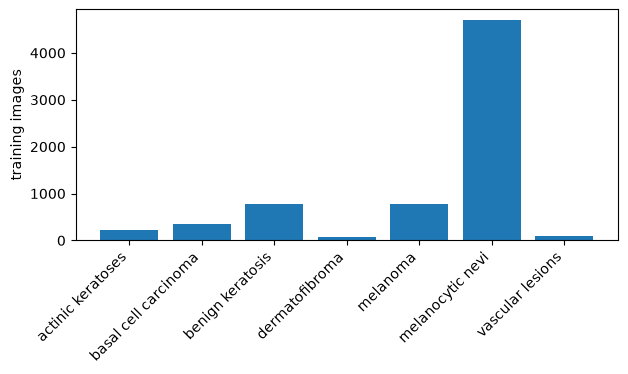

actinic keratoses        228  (3 %)
basal cell carcinoma     359  (5 %)
benign keratosis         769  (11 %)
dermatofibroma            80  (1 %)
melanoma                 779  (11 %)
melanocytic nevi        4693  (67 %)
vascular lesions          99  (1 %)


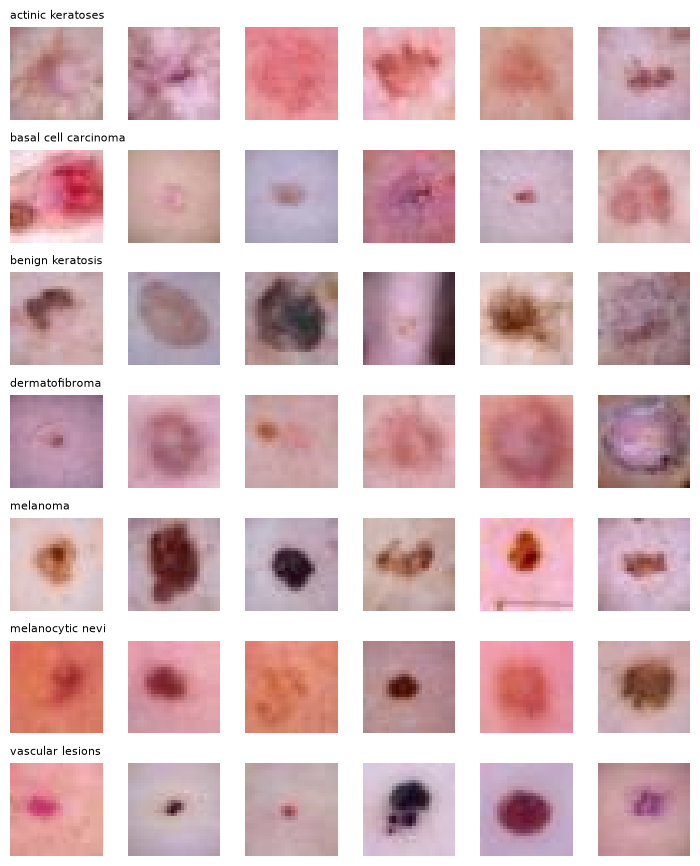

In [3]:
counts = torch.bincount(y_train, minlength=len(CLASSES))
plt.figure(figsize=(7, 3))
plt.bar(CLASSES, counts)
plt.xticks(rotation=45, ha="right"); plt.ylabel("training images"); plt.show()
for name, n in zip(CLASSES, counts):
    print(f"{name:22s} {int(n):5d}  ({100 * n / len(y_train):.0f} %)")

show_examples(X_train, y_train)

❓ **Think:** two thirds of the images are *melanocytic nevi* (harmless moles). A model that always says
"nevus" gets about 67 % accuracy. That is why the **main metric is balanced accuracy** = the average
sensitivity over all 7 classes. What balanced accuracy does the "always nevus" model get?

<details><summary>👀 Answer</summary>

- sensitivity 100 % for nevi, 0 % for the 6 other classes → balanced accuracy = 100 / 7 ≈ **14 %**
- the counts (training): 228, 359, 769, 80, 779, **4693**, 99
</details>

## 2. The baseline CNN (= "A")
The CNN from the day-4 lab, now with **3 input channels** (colour) and **7 classes**.

In [4]:
torch.manual_seed(0)
model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),   # 3 x 28 x 28  -> 16 x 28 x 28
    nn.ReLU(),
    nn.MaxPool2d(2),                              #              -> 16 x 14 x 14
    nn.Conv2d(16, 32, kernel_size=3, padding=1),  #              -> 32 x 14 x 14
    nn.ReLU(),
    nn.MaxPool2d(2),                              #              -> 32 x 7 x 7
    nn.Flatten(),                                 #              -> 1568
    nn.Linear(32 * 7 * 7, len(CLASSES)),          #              -> 7 logits (one raw score per class)
)
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 16071


The training loop - exactly the loop from day 3: forward, loss, `zero_grad`, `backward`, `step`.

In [5]:
EPOCHS = 10      # 👈
LR = 1e-3        # 👈

loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
opt = torch.optim.Adam(model.parameters(), lr=LR)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(EPOCHS):
    model.train()                                  # train mode
    for x, y in loader:
        loss = loss_fn(model(x), y)                # forward: how wrong are we?
        opt.zero_grad()
        loss.backward()                            # backward: gradients
        opt.step()                                 # update the weights
    val_pred = predict(model, X_val)               # eval mode + no_grad inside
    print("epoch", epoch + 1, "  last batch loss", round(loss.item(), 3),
          "  val balanced accuracy", round(balanced_accuracy_score(y_val, val_pred), 3))

epoch 1   last batch loss 0.669   val balanced accuracy 0.242
epoch 2   last batch loss 0.68   val balanced accuracy 0.325
epoch 3   last batch loss 0.794   val balanced accuracy 0.329
epoch 4   last batch loss 0.991   val balanced accuracy 0.351
epoch 5   last batch loss 0.516   val balanced accuracy 0.381
epoch 6   last batch loss 0.486   val balanced accuracy 0.422
epoch 7   last batch loss 0.685   val balanced accuracy 0.423
epoch 8   last batch loss 0.335   val balanced accuracy 0.391
epoch 9   last batch loss 0.586   val balanced accuracy 0.421
epoch 10   last batch loss 0.531   val balanced accuracy 0.432


## 3. Evaluate on the validation images

balanced_accuracy  0.432
accuracy           0.751
macro_F1           0.443
sensitivity per class:
   actinic keratoses      0.45
   basal cell carcinoma   0.50
   benign keratosis       0.49
   dermatofibroma         0.00
   melanoma               0.38
   melanocytic nevi       0.91
   vascular lesions       0.29


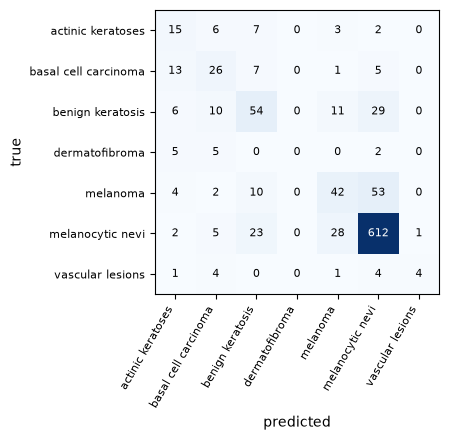

In [6]:
val_pred = predict(model, X_val)
baseline_metrics = challenge_metrics(y_val, val_pred)
show_confusion(y_val, val_pred)

<details><summary>👀 What you should see (CPU: about 1 s per epoch)</summary>

- 16 071 parameters; the validation balanced accuracy climbs from **0.24** (epoch 1) to about **0.44** (epoch 10)
- accuracy **0.75**, but balanced accuracy only **0.44** and macro-F1 **0.45** - the model likes to say "nevus"
- sensitivity: nevi **0.91**, but dermatofibroma **0.00** and vascular lesions **0.29** - the rare classes are missed
- the confusion matrix: most mistakes end up in the "melanocytic nevi" column
- exact numbers change a little from run to run - that is why you use several seeds
</details>

## 4. Export the model - this is what you hand in
TorchScript saves the model *together with its code*: `model.pt` can be loaded without your notebook.
Your `model.pt` must take normalised images `(N, 3, 28, 28)` and return logits `(N, 7)`.

In [7]:
model.eval()
scripted = torch.jit.script(model)          # turn the model into TorchScript
scripted.save("model.pt")                   # this file goes into your submission

loaded = torch.jit.load("model.pt")         # test: load it again, like the evaluation script does
same = torch.equal(predict(loaded, X_val), predict(model, X_val))
print("model.pt saved -", os.path.getsize("model.pt") // 1024, "KB - same predictions after loading:", same)
print("output shape for 2 images:", tuple(loaded(X_val[:2]).shape))

model.pt saved - 75 KB - same predictions after loading: True
output shape for 2 images: (2, 7)


c:\Users\Kaustubh\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\Kaustubh\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


✅ You should see `same predictions after loading: True` and `output shape for 2 images: (2, 7)`.
Download `model.pt`: folder icon on the left in Colab → right-click → *Download*.

## 5. Your turn: improve the baseline (= "B")
Each experiment: change **one** thing, train with **3 seeds**, compare with the baseline (mean ± std), and
compute the 95 % interval of the difference (day 3). Some ideas:

| idea | how | why |
|---|---|---|
| class weights | `class_weights=` in `train(...)` (example below) | rare classes count more (day 3) |
| augmentation | `augment=True` (random flips) - or more: rotations, colour jitter | more variety, less overfitting |
| train longer / learning-rate schedule | `epochs=`, a scheduler (day 3) | the baseline is not finished after 10 epochs |
| a bigger CNN | more filters, a third conv block, BatchNorm, dropout | more capacity |
| a pretrained ResNet | day 5: transfer learning | features learned on millions of images |

Find at least one idea in a paper or a good source and cite it in your report.

📈 **Track your experiments** with one of these free tools - then no result gets lost, and a screenshot of your
runs fits nicely into the report (day 3, "Keep track of your runs"):

| tool | what you get | how to start |
|---|---|---|
| [Weights & Biases](https://wandb.ai) | online dashboard, compare runs, sweeps | free (academic) account; `wandb.init(project=...)`, `wandb.log({...})` |
| [MLflow](https://mlflow.org) | open source, runs stored in a local folder or on a server | `mlflow.start_run()`, `mlflow.log_param(...)`, `mlflow.log_metric(...)` |
| [ClearML](https://clear.ml) | open source, free hosted tier, logs PyTorch runs automatically | free account; `Task.init(project_name=..., task_name=...)` |

In [8]:
CLASS_WEIGHTS = True   # 👈 True: weight = (number of images) / (7 x images of this class)
AUGMENT = False        # 👈
SEEDS = [0, 1, 2]      # 👈 at least 3 seeds


def make_baseline():
    return nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(32 * 7 * 7, len(CLASSES)))


weights = len(y_train) / (len(CLASSES) * counts.float()) if CLASS_WEIGHTS else None
results_a, results_b = [], []
for seed in SEEDS:
    torch.manual_seed(seed)
    pred_a = predict(train(make_baseline(), seed=seed), X_val)                              # A: baseline
    torch.manual_seed(seed)
    pred_b = predict(train(make_baseline(), class_weights=weights, augment=AUGMENT, seed=seed), X_val)  # B
    results_a.append(balanced_accuracy_score(y_val, pred_a))
    results_b.append(balanced_accuracy_score(y_val, pred_b))
    print("seed", seed, "  A:", round(results_a[-1], 3), "  B:", round(results_b[-1], 3),
          "  95 % interval of B - A:", bootstrap_difference(y_val, pred_a, pred_b))

a, b = torch.tensor(results_a), torch.tensor(results_b)
print("A: mean", round(a.mean().item(), 3), "± std", round(a.std().item(), 3))
print("B: mean", round(b.mean().item(), 3), "± std", round(b.std().item(), 3))

seed 0   A: 0.482   B: 0.543   95 % interval of B - A: (0.004, 0.119)
seed 1   A: 0.471   B: 0.545   95 % interval of B - A: (0.022, 0.129)
seed 2   A: 0.442   B: 0.519   95 % interval of B - A: (0.016, 0.138)
A: mean 0.465 ± std 0.021
B: mean 0.535 ± std 0.015


## 6. Our experiments
Every experiment changes exactly ONE thing compared to the baseline (same model, 10 epochs,
lr 0.001, batch size 64). Each is trained with seeds 0, 1, 2. We report the mean ± std of the
balanced accuracy on the validation images and the 95 % bootstrap interval of the difference to
the baseline (same seed).

In [9]:
def make_model(batchnorm=False, dropout=0.0):
    """Baseline CNN from the starter. Optional: BatchNorm after each conv, dropout before the last layer."""
    layers = [nn.Conv2d(3, 16, 3, padding=1)]
    if batchnorm:
        layers.append(nn.BatchNorm2d(16))
    layers += [nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, padding=1)]
    if batchnorm:
        layers.append(nn.BatchNorm2d(32))
    layers += [nn.ReLU(), nn.MaxPool2d(2), nn.Flatten()]
    if dropout > 0:
        layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(32 * 7 * 7, len(CLASSES)))
    return nn.Sequential(*layers)


CLASS_WEIGHTS = len(y_train) / (len(CLASSES) * counts.float())   # N / (7 * n_c)


def train_model(seed, batchnorm=False, dropout=0.0, class_weights=False, augment=False,
                scheduler=False, epochs=10, lr=1e-3):
    """One training run. All switches off = exactly the starter baseline."""
    torch.manual_seed(seed)
    model = make_model(batchnorm, dropout)
    torch.manual_seed(seed)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS if class_weights else None)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=5, gamma=0.5) if scheduler else None
    for epoch in range(epochs):
        model.train()
        for x, y in loader:
            if augment:                                    # random horizontal + vertical flips
                flip = torch.rand(len(x)) < 0.5
                x = torch.where(flip[:, None, None, None], x.flip(-1), x)
                flip = torch.rand(len(x)) < 0.5
                x = torch.where(flip[:, None, None, None], x.flip(-2), x)
            loss = loss_fn(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        if sched:
            sched.step()
    return model


SEEDS = [0, 1, 2]
RESULTS = {}      # name -> balanced accuracy per seed
MODELS = {}       # name -> trained model per seed
PREDS = {}        # name -> validation predictions per seed


def run_experiment(name, **settings):
    """Train with 3 seeds, compare every seed with the baseline of the same seed."""
    MODELS[name], PREDS[name], RESULTS[name] = [], [], []
    for i, seed in enumerate(SEEDS):
        model = train_model(seed, **settings)
        pred = predict(model, X_val)
        MODELS[name].append(model)
        PREDS[name].append(pred)
        RESULTS[name].append(balanced_accuracy_score(y_val, pred))
        line = f"seed {seed}: {name} {RESULTS[name][-1]:.3f}"
        if name != "Baseline":
            line += (f"   baseline {RESULTS['Baseline'][i]:.3f}   95 % interval of difference: "
                     f"{bootstrap_difference(y_val, PREDS['Baseline'][i], pred)}")
        print(line)
    r = torch.tensor(RESULTS[name])
    print(f"==> {name}: mean {r.mean().item():.3f} ± std {r.std().item():.3f}")


print("experiment tools ready")

experiment tools ready


In [10]:
run_experiment("Baseline")

seed 0: Baseline 0.482
seed 1: Baseline 0.471
seed 2: Baseline 0.442
==> Baseline: mean 0.465 ± std 0.021


### Experiment 1 – Class weights
Two thirds of the images are nevi, so the plain loss lets the model ignore rare classes.
Each class gets the weight N / (7 · n_c), so every class counts equally in the loss.
Source: Y. Cui et al., "Class-Balanced Loss Based on Effective Number of Samples", CVPR 2019.

In [11]:
run_experiment("Class weights", class_weights=True)

seed 0: Class weights 0.543   baseline 0.482   95 % interval of difference: (0.004, 0.119)
seed 1: Class weights 0.545   baseline 0.471   95 % interval of difference: (0.022, 0.129)
seed 2: Class weights 0.519   baseline 0.442   95 % interval of difference: (0.016, 0.138)
==> Class weights: mean 0.535 ± std 0.015


**Result:** 0.535 ± 0.015 vs. baseline 0.465 ± 0.021 (+0.070).
95 % intervals of the difference: seed 0 (0.004, 0.119), seed 1 (0.022, 0.129), seed 2 (0.016, 0.138).
All three intervals lie above zero, so class weighting is a clear improvement. The model now
pays more attention to the rare classes instead of predicting "nevus" most of the time.

### Experiment 2 – Data augmentation
Random horizontal and vertical flips. Skin lesions have no "up", so flipped images are still realistic.
Source: C. Shorten, T. M. Khoshgoftaar, "A survey on Image Data Augmentation for Deep Learning", J. Big Data 2019.

In [12]:
run_experiment("Augmentation", augment=True)

seed 0: Augmentation 0.461   baseline 0.482   95 % interval of difference: (-0.054, 0.013)
seed 1: Augmentation 0.414   baseline 0.471   95 % interval of difference: (-0.113, -0.004)
seed 2: Augmentation 0.474   baseline 0.442   95 % interval of difference: (-0.003, 0.064)
==> Augmentation: mean 0.450 ± std 0.032


**Result:** 0.450 ± 0.032 vs. baseline 0.465 ± 0.021 (−0.015).
95 % intervals of the difference: seed 0 (−0.054, 0.013), seed 1 (−0.113, −0.004), seed 2 (−0.003, 0.064).
Two intervals include zero and one lies below zero, so augmentation did not help in this setting.
A likely reason: flipped images make the training task harder, and our small CNN, trained for only
10 epochs, has too little capacity and time to profit from the extra variety. Augmentation usually
helps bigger models trained for longer.

### Experiment 3 – Batch Normalisation
BatchNorm after each convolution normalises the activations, which can make training faster and more stable.
Source: S. Ioffe, C. Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing
Internal Covariate Shift", ICML 2015.

In [13]:
run_experiment("BatchNorm", batchnorm=True)

seed 0: BatchNorm 0.495   baseline 0.482   95 % interval of difference: (-0.023, 0.053)
seed 1: BatchNorm 0.486   baseline 0.471   95 % interval of difference: (-0.024, 0.059)
seed 2: BatchNorm 0.426   baseline 0.442   95 % interval of difference: (-0.06, 0.024)
==> BatchNorm: mean 0.469 ± std 0.037


**Result:** 0.469 ± 0.037 vs. baseline 0.465 ± 0.021 (+0.004).
95 % intervals of the difference: seed 0 (−0.023, 0.053), seed 1 (−0.024, 0.059), seed 2 (−0.060, 0.024).
All three intervals include zero, so BatchNorm gives no clear improvement, and the results vary more
between seeds. With only two conv layers, our network is shallow enough to train stably without it;
BatchNorm mainly helps deeper networks.

### Experiment 4 – Dropout
Dropout (p = 0.5) before the last layer randomly switches off half of the features during training,
to reduce overfitting.
Source: N. Srivastava et al., "Dropout: A Simple Way to Prevent Neural Networks from Overfitting", JMLR 2014.

In [14]:
run_experiment("Dropout", dropout=0.5)

seed 0: Dropout 0.431   baseline 0.482   95 % interval of difference: (-0.1, -0.006)
seed 1: Dropout 0.421   baseline 0.471   95 % interval of difference: (-0.086, -0.018)
seed 2: Dropout 0.398   baseline 0.442   95 % interval of difference: (-0.09, -0.001)
==> Dropout: mean 0.417 ± std 0.017


**Result:** 0.417 ± 0.017 vs. baseline 0.465 ± 0.021 (−0.048).
95 % intervals of the difference: seed 0 (−0.100, −0.006), seed 1 (−0.086, −0.018), seed 2 (−0.090, −0.001).
All three intervals lie below zero, so dropout clearly made the model worse. Our baseline has only
16 071 parameters and is underfitting rather than overfitting (its validation balanced accuracy was
still rising at epoch 10), so switching off half of the features removes useful signal instead of
preventing overfitting. A lower rate (e.g. p = 0.2) or longer training might change this.

### Experiment 5 – Learning-rate scheduler
StepLR halves the learning rate every 5 epochs, so the model makes smaller, finer updates late in training.
Source: I. Goodfellow, Y. Bengio, A. Courville, "Deep Learning", MIT Press 2016, Sec. 8.3.

In [15]:
run_experiment("Scheduler", scheduler=True)

seed 0: Scheduler 0.502   baseline 0.482   95 % interval of difference: (-0.002, 0.05)
seed 1: Scheduler 0.481   baseline 0.471   95 % interval of difference: (-0.027, 0.046)
seed 2: Scheduler 0.445   baseline 0.442   95 % interval of difference: (-0.023, 0.024)
==> Scheduler: mean 0.476 ± std 0.029


**Result:** 0.476 ± 0.029 vs. baseline 0.465 ± 0.021 (+0.011).
95 % intervals of the difference: seed 0 (−0.002, 0.050), seed 1 (−0.027, 0.046), seed 2 (−0.023, 0.024).
The mean improves slightly and all three seeds are at least as good as the baseline, but every
interval includes zero, so the gain is not clear. Smaller steps late in training help a little,
but 10 epochs leave little room for the schedule to make a difference.

In [16]:
print(f"{'Experiment':30s} {'mean':>6s}   std")
for name, scores in RESULTS.items():
    r = torch.tensor(scores)
    print(f"{name:30s} {r.mean().item():6.3f} ± {r.std().item():.3f}")

Experiment                       mean   std
Baseline                        0.465 ± 0.021
Class weights                   0.535 ± 0.015
Augmentation                    0.450 ± 0.032
BatchNorm                       0.469 ± 0.037
Dropout                         0.417 ± 0.017
Scheduler                       0.476 ± 0.029


## 7. Final model
Class weights gave the only clear improvement; the scheduler and BatchNorm gave small, uncertain
gains. We test whether adding them on top of class weights helps, and choose the final model by its
mean validation balanced accuracy (never the test set).

In [17]:
run_experiment("CW + scheduler", class_weights=True, scheduler=True)
run_experiment("CW + scheduler + BatchNorm", class_weights=True, scheduler=True, batchnorm=True)

seed 0: CW + scheduler 0.548   baseline 0.482   95 % interval of difference: (0.008, 0.126)
seed 1: CW + scheduler 0.517   baseline 0.471   95 % interval of difference: (-0.003, 0.098)
seed 2: CW + scheduler 0.516   baseline 0.442   95 % interval of difference: (0.016, 0.135)
==> CW + scheduler: mean 0.527 ± std 0.018
seed 0: CW + scheduler + BatchNorm 0.576   baseline 0.482   95 % interval of difference: (0.035, 0.157)
seed 1: CW + scheduler + BatchNorm 0.570   baseline 0.471   95 % interval of difference: (0.046, 0.149)
seed 2: CW + scheduler + BatchNorm 0.553   baseline 0.442   95 % interval of difference: (0.052, 0.173)
==> CW + scheduler + BatchNorm: mean 0.566 ± std 0.012


**Result:**

| Model | Balanced accuracy (val) |
|---|---:|
| Baseline | 0.465 ± 0.021 |
| Class weights | 0.535 ± 0.015 |
| CW + scheduler | 0.527 ± 0.018 |
| CW + scheduler + BatchNorm | **0.566 ± 0.012** |

CW + scheduler + BatchNorm vs. baseline, 95 % intervals: seed 0 (0.035, 0.157),
seed 1 (0.046, 0.149), seed 2 (0.052, 0.173). All three lie clearly above zero.

Adding only the scheduler to class weights did not help (0.527 vs. 0.535). Adding BatchNorm as well
gave the best and most stable result. Interestingly, BatchNorm alone did not help (Experiment 3):
with class weights, the rare classes produce much larger gradients, and BatchNorm keeps the
activations in a stable range, so training with the weighted loss becomes more stable.
We choose **CW + scheduler + BatchNorm** as our final model.

final model: CW + scheduler + BatchNorm - seed 0
balanced_accuracy  0.576
accuracy           0.560
macro_F1           0.406
sensitivity per class:
   actinic keratoses      0.55
   basal cell carcinoma   0.67
   benign keratosis       0.55
   dermatofibroma         0.50
   melanoma               0.57
   melanocytic nevi       0.55
   vascular lesions       0.64


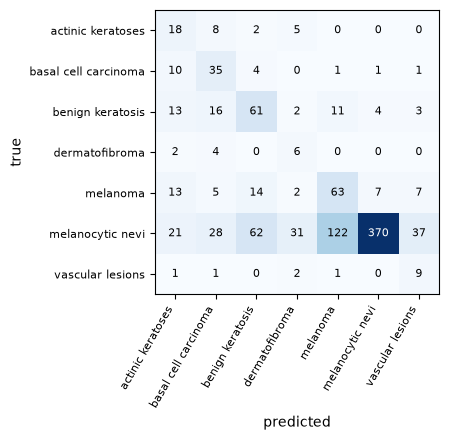

same predictions after loading: True
output shape for 2 images: (2, 7)


c:\Users\Kaustubh\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\Kaustubh\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


In [18]:
FINAL_CANDIDATES = ["Class weights", "CW + scheduler", "CW + scheduler + BatchNorm"]
best_name = max(FINAL_CANDIDATES, key=lambda n: torch.tensor(RESULTS[n]).mean().item())
best_i = max(range(len(SEEDS)), key=lambda i: RESULTS[best_name][i])
final_model = MODELS[best_name][best_i]
print("final model:", best_name, "- seed", SEEDS[best_i])
final_metrics = challenge_metrics(y_val, PREDS[best_name][best_i])
show_confusion(y_val, PREDS[best_name][best_i])

final_model.eval()
torch.jit.script(final_model).save("model.pt")
loaded = torch.jit.load("model.pt")
print("same predictions after loading:", torch.equal(predict(loaded, X_val), predict(final_model, X_val)))
print("output shape for 2 images:", tuple(loaded(X_val[:2]).shape))

**Final model: CW + scheduler + BatchNorm (seed 0), exported as model.pt.**
Validation: balanced accuracy 0.576 (mean over seeds 0.566 ± 0.012), macro-F1 0.406.

Per-class sensitivity: actinic keratoses 0.55, basal cell carcinoma 0.67, benign keratosis 0.55,
dermatofibroma 0.50, melanoma 0.57, melanocytic nevi 0.55, vascular lesions 0.64.

Compared to the baseline, the rare classes are now recognised (dermatofibroma 0.00 → 0.50,
vascular lesions 0.29 → 0.64). The price is a lower sensitivity for nevi (0.91 → 0.55): many nevi
are now predicted as melanoma or benign keratosis. For a screening tool this trade-off is
acceptable – a false alarm leads to an extra check by a doctor, while a missed melanoma can be fatal.

Macro-F1 drops slightly (baseline 0.443 → 0.406): the model now finds the rare classes, but also
raises more false alarms on nevi, which lowers the precision of the rare classes.